Passo 1: calcular a Carta P

In [0]:
g = spark.table("workspace.process_sigma.gold_sigma").orderBy("period").toPandas()

g["p"] = g["total_defects"] / g["total_opportunities"]
p_bar = g["total_defects"].sum() / g["total_opportunities"].sum()

margem = 3 * (p_bar * (1 - p_bar) / g["total_opportunities"]) ** 0.5
g["ucl"] = p_bar + margem
g["lcl"] = (p_bar - margem).clip(lower=0)
g["fora"] = (g["p"] > g["ucl"]) | (g["p"] < g["lcl"])

print(f"p̄ = {p_bar:.4f} | pontos fora de controle: {int(g['fora'].sum())}")
display(g[["period", "total_opportunities", "total_defects", "p", "lcl", "ucl", "fora"]].round(4))

p̄ = 0.5200 | pontos fora de controle: 0


period,total_opportunities,total_defects,p,lcl,ucl,fora
2022-01,62,31,0.5,0.3297,0.7103,false
2022-02,56,27,0.4821,0.3197,0.7203,false
2022-03,62,36,0.5806,0.3297,0.7103,false
2022-04,60,29,0.4833,0.3265,0.7135,false
2022-05,62,31,0.5,0.3297,0.7103,false
2022-06,60,31,0.5167,0.3265,0.7135,false
2022-07,62,33,0.5323,0.3297,0.7103,false
2022-08,62,34,0.5484,0.3297,0.7103,false
2022-09,14,8,0.5714,0.1194,0.9206,false


Passo 2: o gráfico

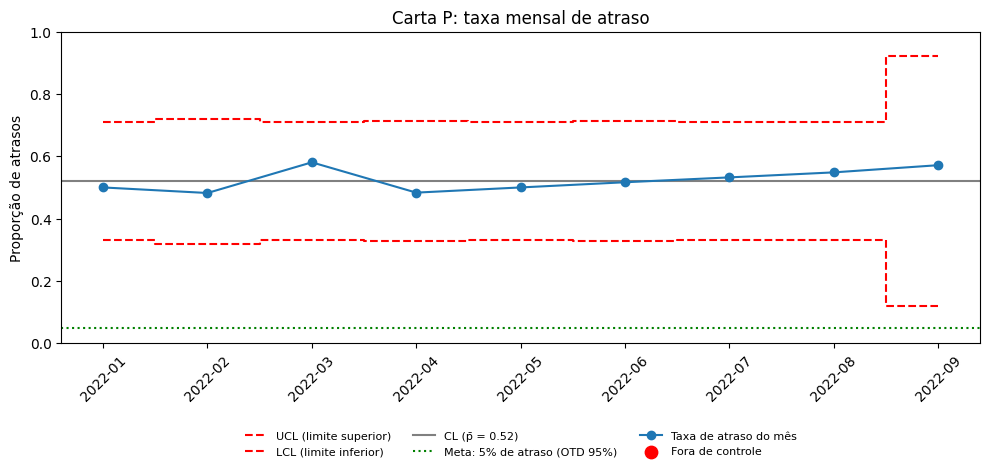

In [0]:
import matplotlib.pyplot as plt

x = g["period"]
fig, ax = plt.subplots(figsize=(10, 5))

ax.step(x, g["ucl"], where="mid", color="red", linestyle="--", label="UCL (limite superior)")
ax.step(x, g["lcl"], where="mid", color="red", linestyle="--", label="LCL (limite inferior)")
ax.axhline(p_bar, color="gray", label=f"CL (p̄ = {p_bar:.2f})")
ax.axhline(0.05, color="green", linestyle=":", label="Meta: 5% de atraso (OTD 95%)")
ax.plot(x, g["p"], marker="o", color="#1f77b4", label="Taxa de atraso do mês")

fora = g[g["fora"]]
ax.scatter(fora["period"], fora["p"], color="red", s=80, zorder=5, label="Fora de controle")

ax.set_ylim(0, 1)
ax.set_ylabel("Proporção de atrasos")
ax.set_title("Carta P: taxa mensal de atraso")
ax.legend(
    loc="upper center",          # âncora da legenda: o topo-centro dela
    bbox_to_anchor=(0.5, -0.25), # onde ela encosta: 50% na horizontal, 25% ABAIXO do eixo
    ncol=3,                      # 3 colunas, para ficar larga e baixa
    fontsize=8,
    frameon=False,
)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

Primeiro gráfico: o histograma de delay_days. Pergunta que ele responde: o carteiro erra para mais ou para menos, e por quanto?

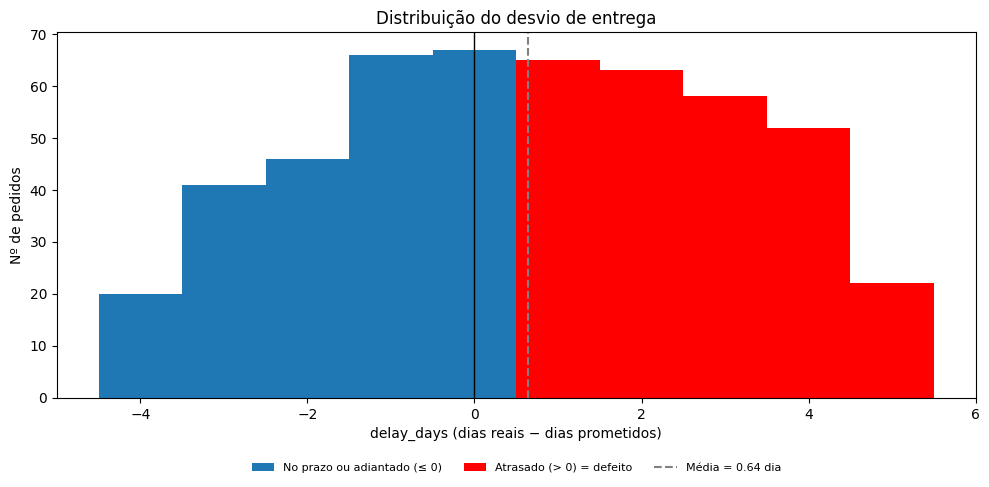

In [0]:
import matplotlib.pyplot as plt
import numpy as np

# 1) Traz a Silver do Delta para o pandas (500 linhas, cabe fácil)
silver = spark.table("workspace.process_sigma.silver_orders").toPandas()
d = silver["delay_days"]

# 2) Uma barra por dia inteiro: bins centrados em cada número
bins = np.arange(d.min() - 0.5, d.max() + 1.5, 1)

# 3) Duas camadas com os mesmos bins: no prazo (azul) e atrasado (vermelho)
fig, ax = plt.subplots(figsize=(10, 5))
ax.hist(d[d <= 0], bins=bins, color="#1f77b4", label="No prazo ou adiantado (≤ 0)")
ax.hist(d[d > 0],  bins=bins, color="red",     label="Atrasado (> 0) = defeito")

# 4) Duas linhas de referência
ax.axvline(0, color="black", linewidth=1)
ax.axvline(d.mean(), color="gray", linestyle="--", label=f"Média = {d.mean():.2f} dia")

ax.set_xlabel("delay_days (dias reais − dias prometidos)")
ax.set_ylabel("Nº de pedidos")
ax.set_title("Distribuição do desvio de entrega")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.15), ncol=3, fontsize=8, frameon=False)
plt.tight_layout()
plt.show()

In [0]:
print("média:", round(d.mean(), 2))
print("mediana:", d.median())
print("assimetria (skew):", round(d.skew(), 2))
print("desvio:", round(d.std(), 2))

média: 0.64
mediana: 1.0
assimetria (skew): -0.06
desvio: 2.43


Gráfico 2: OTD por região. Pergunta dele: o atraso é de um bairro específico ou da cidade inteira?

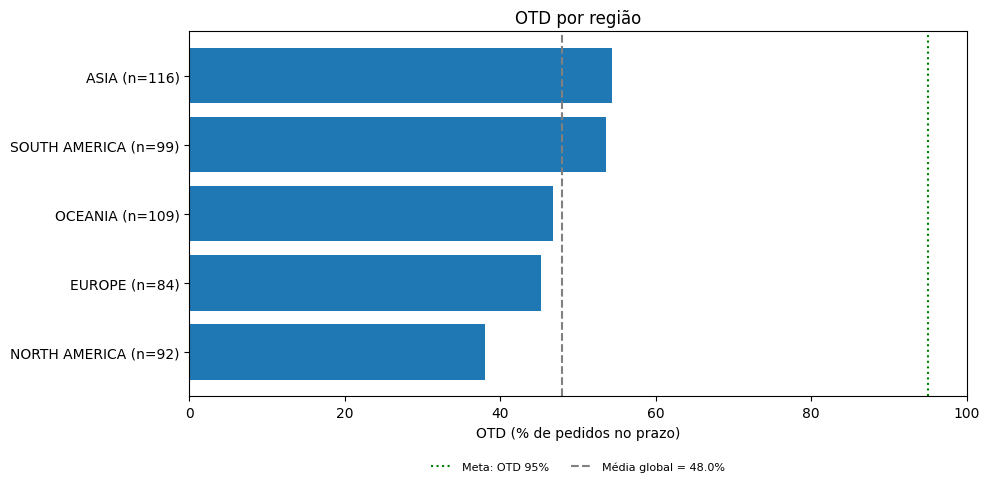

In [0]:
# 1) OTD por região direto da Silver: % de pedidos NÃO atrasados
g_reg = silver.groupby("order_region").agg(
    pedidos=("is_late", "size"),
    otd=("is_late", lambda s: (1 - s.mean()) * 100),
).sort_values("otd")

otd_global = (1 - silver["is_late"].mean()) * 100

# 2) Barras horizontais, com o nº de pedidos no rótulo
fig, ax = plt.subplots(figsize=(10, 5))
rotulos = [f"{r} (n={n})" for r, n in zip(g_reg.index, g_reg["pedidos"])]
ax.barh(rotulos, g_reg["otd"], color="#1f77b4")

# 3) Duas linhas de referência
ax.axvline(95, color="green", linestyle=":", label="Meta: OTD 95%")
ax.axvline(otd_global, color="gray", linestyle="--", label=f"Média global = {otd_global:.1f}%")

ax.set_xlim(0, 100)
ax.set_xlabel("OTD (% de pedidos no prazo)")
ax.set_title("OTD por região")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.15), ncol=2, fontsize=8, frameon=False)
plt.tight_layout()
plt.show()

Gráfico 3: tendência mensal. Pergunta dele: está melhorando, piorando ou parado?

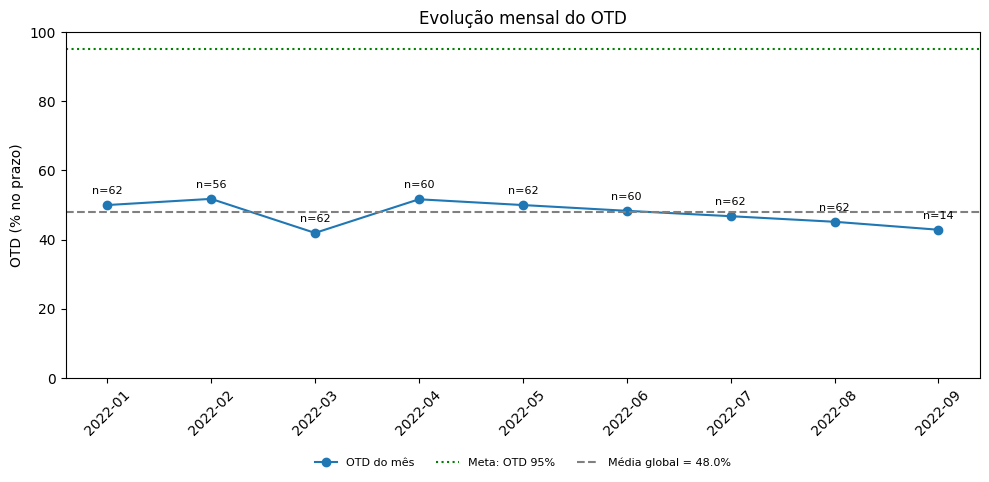

In [0]:
# 1) OTD e nº de pedidos por mês, direto da Silver
mensal = (
    silver.groupby("period")
    .agg(pedidos=("is_late", "size"),
         otd=("is_late", lambda s: (1 - s.mean()) * 100))
    .reset_index()
    .sort_values("period")
)
otd_global = (1 - silver["is_late"].mean()) * 100
x = mensal["period"].astype(str)

# 2) Linha do OTD, com n= em cada ponto
fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(x, mensal["otd"], marker="o", color="#1f77b4", label="OTD do mês")
for xi, yi, n in zip(x, mensal["otd"], mensal["pedidos"]):
    ax.annotate(f"n={n}", (xi, yi), textcoords="offset points",
                xytext=(0, 8), ha="center", fontsize=8)

# 3) Referências
ax.axhline(95, color="green", linestyle=":", label="Meta: OTD 95%")
ax.axhline(otd_global, color="gray", linestyle="--", label=f"Média global = {otd_global:.1f}%")

ax.set_ylim(0, 100)
ax.set_ylabel("OTD (% no prazo)")
ax.set_title("Evolução mensal do OTD")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.2), ncol=3, fontsize=8, frameon=False)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [0]:
sem_set = mensal.iloc[:-1]   # tira o último mês (setembro)
acima  = (sem_set["otd"] > otd_global).sum()
abaixo = (sem_set["otd"] < otd_global).sum()
print(f"Meses acima da média: {acima} | abaixo: {abaixo}")
print(mensal[["period", "pedidos", "otd"]].round(1).to_string(index=False))

Meses acima da média: 5 | abaixo: 3
 period  pedidos  otd
2022-01       62 50.0
2022-02       56 51.8
2022-03       62 41.9
2022-04       60 51.7
2022-05       62 50.0
2022-06       60 48.3
2022-07       62 46.8
2022-08       62 45.2
2022-09       14 42.9


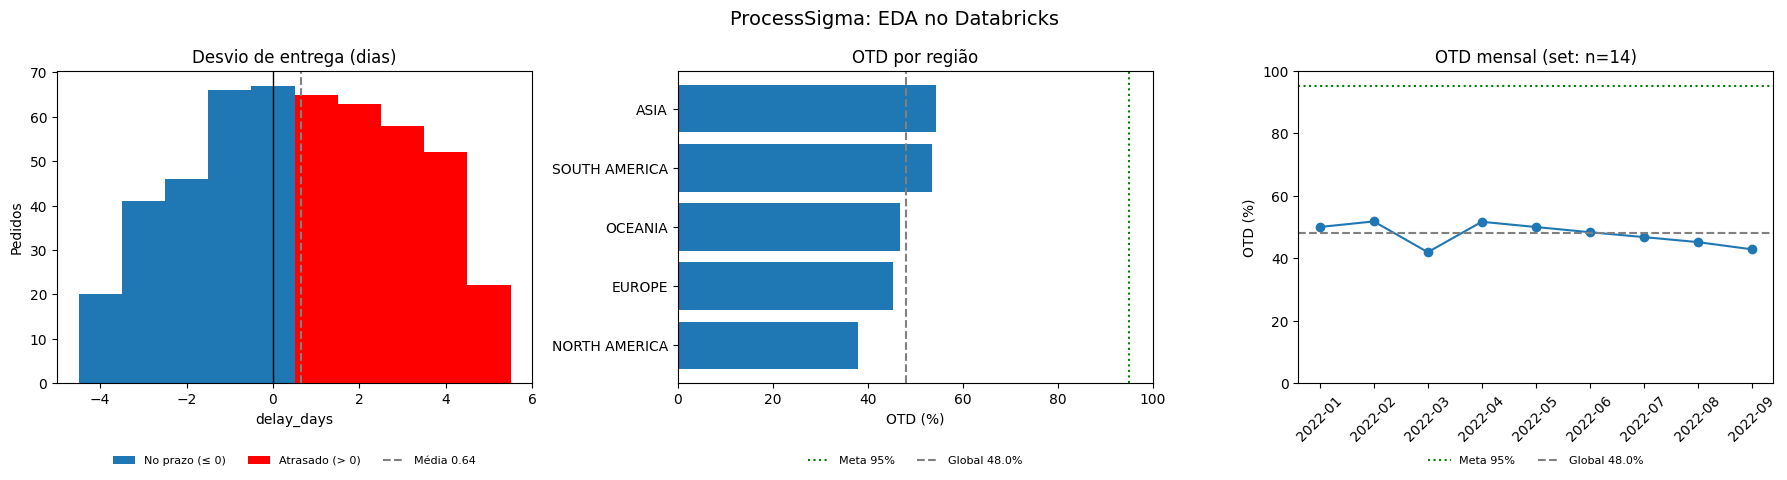

In [0]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Painel 1: histograma do desvio
ax = axes[0]
ax.hist(d[d <= 0], bins=bins, color="#1f77b4", label="No prazo (≤ 0)")
ax.hist(d[d > 0],  bins=bins, color="red",     label="Atrasado (> 0)")
ax.axvline(0, color="black", linewidth=1)
ax.axvline(d.mean(), color="gray", linestyle="--", label=f"Média {d.mean():.2f}")
ax.set_title("Desvio de entrega (dias)")
ax.set_xlabel("delay_days"); ax.set_ylabel("Pedidos")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.2), ncol=3, fontsize=8, frameon=False)

# Painel 2: OTD por região
ax = axes[1]
ax.barh(g_reg.index, g_reg["otd"], color="#1f77b4")
ax.axvline(95, color="green", linestyle=":", label="Meta 95%")
ax.axvline(otd_global, color="gray", linestyle="--", label=f"Global {otd_global:.1f}%")
ax.set_xlim(0, 100)
ax.set_title("OTD por região")
ax.set_xlabel("OTD (%)")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.2), ncol=3, fontsize=8, frameon=False)

# Painel 3: OTD mensal
ax = axes[2]
x = mensal["period"].astype(str)
ax.plot(x, mensal["otd"], marker="o", color="#1f77b4")
ax.axhline(95, color="green", linestyle=":", label="Meta 95%")
ax.axhline(otd_global, color="gray", linestyle="--", label=f"Global {otd_global:.1f}%")
ax.set_ylim(0, 100)
ax.set_title("OTD mensal (set: n=14)")
ax.set_ylabel("OTD (%)")
ax.tick_params(axis="x", rotation=45)
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.2), ncol=3, fontsize=8, frameon=False)

fig.suptitle("ProcessSigma: EDA no Databricks", fontsize=14)
plt.tight_layout()
plt.show()